# 1. Import Libraries and Load the Dataset

In this section, we import the required Python libraries and load the SMS Spam Collection dataset for spam and ham message classification.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


# 2. Data Exploration and Class Distribution

In this section, we examine the dataset structure, check for missing values and duplicate messages, and compare the number and percentage of spam and ham messages.

In [3]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nLabel counts:")
print(df["label"].value_counts())

Dataset shape: (5572, 2)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 542.9 KB

Missing values:
label      0
message    0
dtype: int64

Label counts:
label
ham     4825
spam     747
Name: count, dtype: int64


Message counts:


label
ham     4825
spam     747
Name: count, dtype: int64


Message percentages:


label
ham     86.59
spam    13.41
Name: proportion, dtype: float64

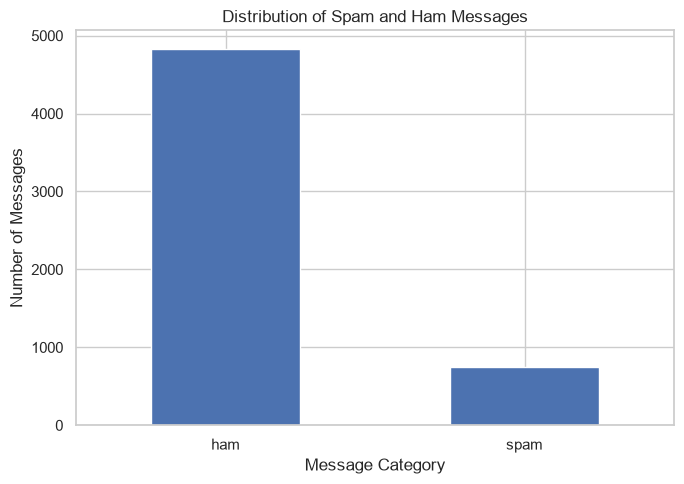

In [4]:
label_counts = df["label"].value_counts()

label_percentages = (
    df["label"].value_counts(normalize=True) * 100
)

print("Message counts:")
display(label_counts)

print("\nMessage percentages:")
display(label_percentages.round(2))

plt.figure(figsize=(7, 5))
label_counts.plot(kind="bar")
plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [5]:
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)

Duplicate rows: 403
Dataset shape after removing duplicates: (5169, 2)


# 3. Text Preprocessing

In this section, we prepare the message text for machine learning by converting text to lowercase, removing punctuation and unnecessary characters, and removing common stopwords. This helps standardize the text and reduce less useful information.

In [6]:
print("Unique labels:", df["label"].unique())
print("\nLabel counts:")
print(df["label"].value_counts())

Unique labels: <ArrowStringArray>
['ham', 'spam']
Length: 2, dtype: str

Label counts:
label
ham     4516
spam     653
Name: count, dtype: int64


In [7]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_message"] = df["message"].apply(clean_text)

df[["label", "message", "clean_message"]].head()

,label,message,clean_message
0,ham,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...


In [8]:
print("Original message:")
print(df["message"].iloc[0])

print("\nCleaned message:")
print(df["clean_message"].iloc[0])

Original message:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Cleaned message:
go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat


# 4. TF-IDF Feature Extraction

Machine learning algorithms require numerical input rather than raw text. Term Frequency–Inverse Document Frequency (TF-IDF) converts messages into numerical feature vectors. It gives greater importance to words that are frequent in a message but less common across the overall collection of messages.

TF-IDF will be fitted on the training messages only. The same fitted transformation will then be applied to the test messages. We will use a scikit-learn Pipeline to keep feature extraction and classification together and prevent data leakage.

# 5. Train-Test Split

In this section, we divide the dataset into training and testing subsets. The training data is used to learn patterns, while the testing data evaluates performance on messages that the model has not seen during training.

In [9]:
X = df["clean_message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))
print("\nTraining label distribution:")
print(y_train.value_counts())

Training messages: 4135
Testing messages: 1034

Training label distribution:
label
ham     3613
spam     522
Name: count, dtype: int64


# 6. Model Training

In this section, we train two machine learning classifiers using TF-IDF features: Multinomial Naive Bayes and Logistic Regression. Both models use the same training and testing split so their performance can be compared fairly.

## 6.1 Multinomial Naive Bayes

Multinomial Naive Bayes is a probabilistic classification algorithm commonly used for text classification. It estimates class probabilities using the features extracted from the training messages. In this project, TF-IDF converts the text into numerical features before the classifier learns from them.

In [10]:
nb_model = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("classifier", MultinomialNB())
])

nb_model.fit(X_train, y_train)

print("Multinomial Naive Bayes training completed!")

Multinomial Naive Bayes training completed!


## 6.2 Logistic Regression

Logistic Regression is a supervised learning algorithm that estimates the probability of a class based on weighted input features. We use it as an alternative to Naive Bayes and compare both models using the same test data and evaluation metrics.

In [11]:
lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("classifier", LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


# 7. Model Evaluation and Comparison

In this section, we evaluate both trained models on the test dataset using accuracy, precision, recall, and F1-score. These metrics provide a more complete understanding of classification performance than accuracy alone.

In [12]:
nb_predictions = nb_model.predict(X_test)
lr_predictions = lr_model.predict(X_test)

results = []

for model_name, predictions in [
    ("Multinomial Naive Bayes", nb_predictions),
    ("Logistic Regression", lr_predictions)
]:
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label="spam", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label="spam", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, pos_label="spam", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Multinomial Naive Bayes,0.9662,1.000,0.7328,0.8458
1,Logistic Regression,0.9574,0.978,0.6794,0.8018


### Why Recall Is Important in Spam Detection

Recall measures the proportion of actual spam messages that the classifier correctly identifies. High spam recall reduces the number of spam messages incorrectly classified as legitimate. This is important because missed spam may contain scams, phishing attempts, or unwanted content. However, precision must also be considered because incorrectly classifying legitimate messages as spam can cause important communications to be missed.

# 8. Confusion Matrix Analysis

A confusion matrix compares the actual labels with the predicted labels. It helps us identify correctly classified messages, spam messages that were missed, and legitimate messages that were incorrectly flagged as spam.

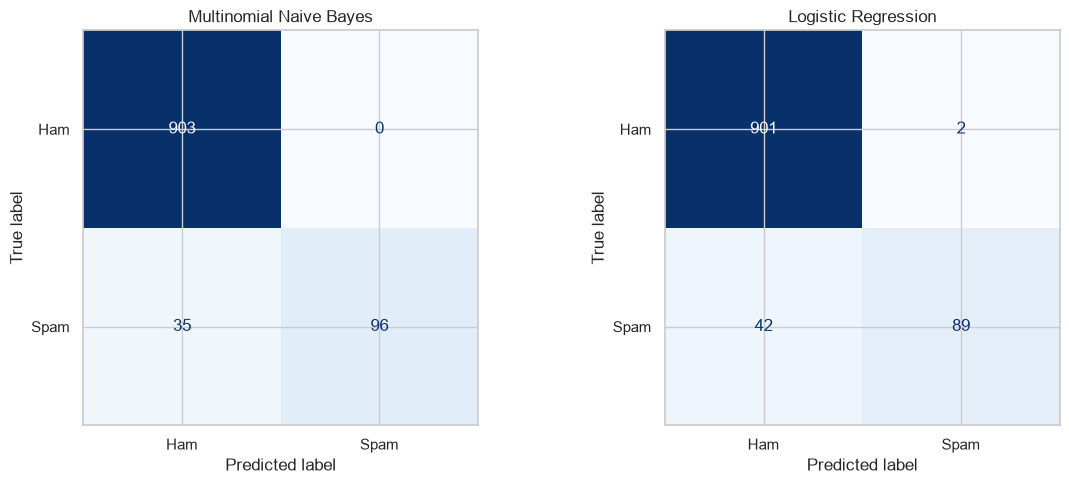

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, model_name, predictions in [
    (axes[0], "Multinomial Naive Bayes", nb_predictions),
    (axes[1], "Logistic Regression", lr_predictions)
]:
    cm = confusion_matrix(
        y_test, predictions, labels=["ham", "spam"]
    )

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Ham", "Spam"]
    )

    display_matrix.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(model_name)

plt.tight_layout()
plt.show()

In [14]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


# 9. WordCloud Visualization

In this section, we create separate WordCloud visualizations for spam and ham messages. These visualizations help us explore frequently occurring words in each category.

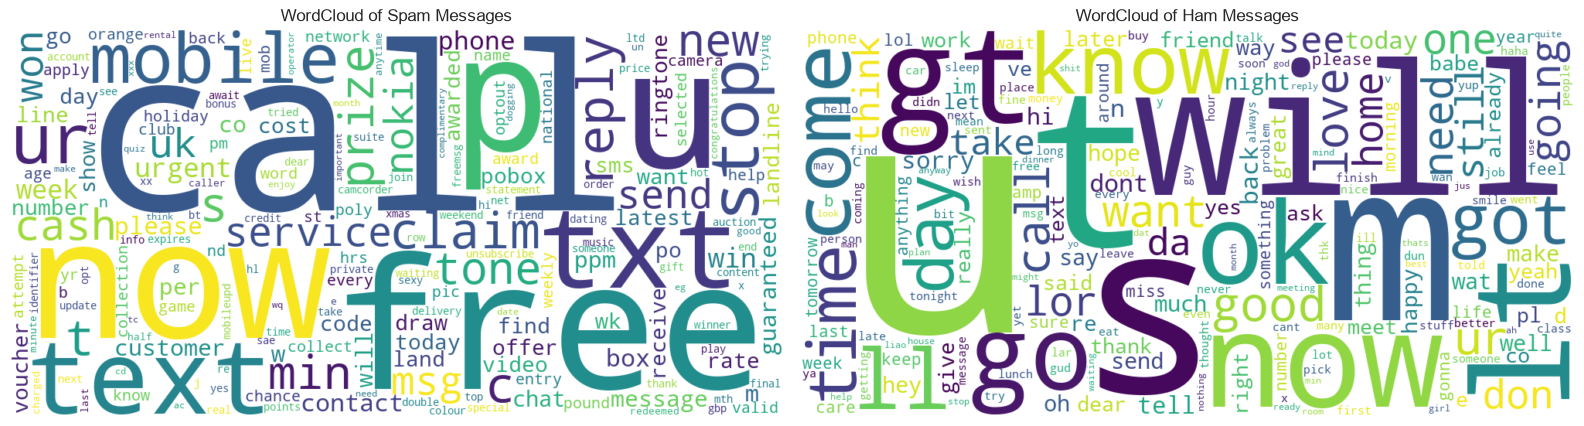

In [15]:
from wordcloud import WordCloud, STOPWORDS

spam_text = " ".join(
    df.loc[df["label"] == "spam", "clean_message"]
)

ham_text = " ".join(
    df.loc[df["label"] == "ham", "clean_message"]
)

stop_words = set(STOPWORDS)

spam_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    stopwords=stop_words,
    collocations=False
).generate(spam_text)

ham_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    stopwords=stop_words,
    collocations=False
).generate(ham_text)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(spam_wordcloud, interpolation="bilinear")
axes[0].set_title("WordCloud of Spam Messages")
axes[0].axis("off")

axes[1].imshow(ham_wordcloud, interpolation="bilinear")
axes[1].set_title("WordCloud of Ham Messages")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# 10. Key Findings and Conclusion

In this section, we compare the evaluation metrics of both classifiers and summarize the main findings from the spam detection experiment.

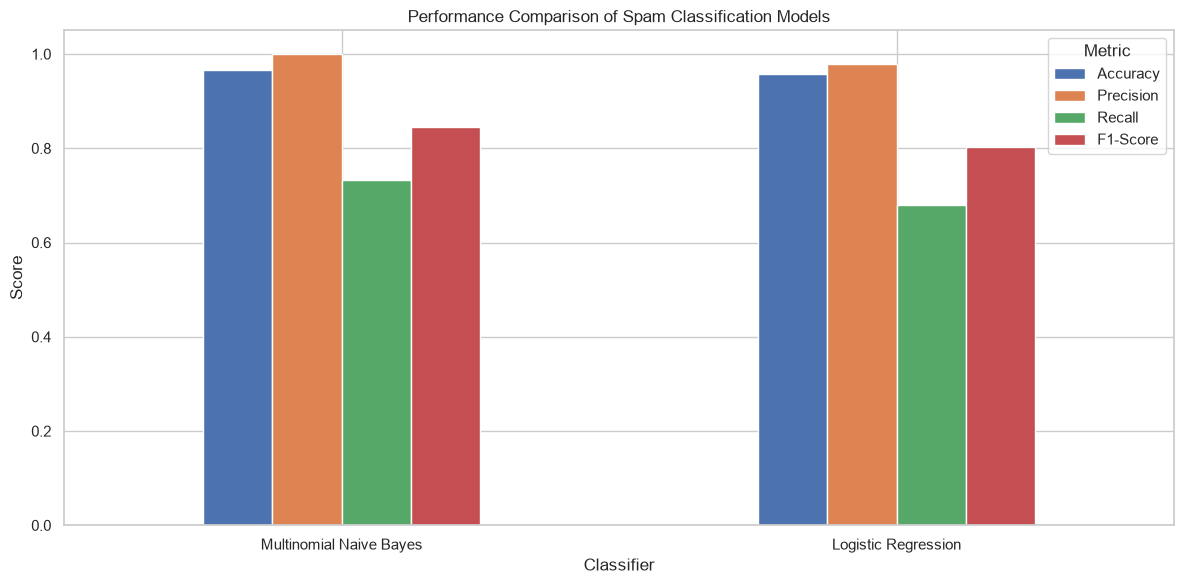

In [16]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of Spam Classification Models")
plt.xlabel("Classifier")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

In [17]:
best_model_row = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("Best model based on spam F1-score:")
print(best_model_row["Model"])
print("F1-score:", round(best_model_row["F1-Score"], 4))
print("Precision:", round(best_model_row["Precision"], 4))
print("Recall:", round(best_model_row["Recall"], 4))

Best model based on spam F1-score:
Multinomial Naive Bayes
F1-score: 0.8458
Precision: 1.0
Recall: 0.7328


## Conclusion

In this project, I developed a spam detection system using Natural Language Processing and machine learning. I explored the SMS Spam Collection dataset, removed duplicate messages, cleaned the text, and converted the messages into numerical features using TF-IDF.

I trained and evaluated two classifiers: Multinomial Naive Bayes and Logistic Regression. Their performance was compared using accuracy, precision, recall, and F1-score, along with confusion matrices.

- **Best model by spam F1-score:** Multinomial Naive Bayes
- **Spam precision:** 1.0
- **Spam recall:** 0.7328
- **Spam F1-score:** 0.8458

The experiment demonstrated how text preprocessing and TF-IDF can be combined with machine learning to classify messages. Recall is especially important because missed spam messages may contain scams or phishing attempts, while precision helps reduce the risk of legitimate messages being incorrectly flagged.

The results apply to this dataset and evaluation split; performance on new, real-world messages may differ.